# Milestones 5-6 - Cross-encoder reranker + fine-tuning

`BAAI/bge-reranker-large` jointly encodes (query, passage) and outputs a relevance logit. It narrows the 30 hybrid candidates to the top 5. We fine-tune it in PyTorch on the project's own labelled pairs with a **pairwise (RankNet) loss** `log(1 + exp(-(s_pos - s_neg)))`, using hard negatives mined from the hybrid retriever. Training facts and test facts are disjoint. Training is run by `scripts/train_reranker.py` (about 45 min on an M4 Max); this notebook re-runs it only if no fine-tuned checkpoint exists.

In [1]:
import os, sys, json, time, warnings, pathlib
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
from rag import config

In [2]:
import subprocess
if not (config.FINETUNED_RERANKER_DIR / "model.safetensors").exists():
    subprocess.run([sys.executable, "scripts/train_reranker.py"], check=True)
hist = json.loads((config.FINETUNED_RERANKER_DIR / "training_history.json").read_text())
comp = json.loads((config.ARTIFACT_DIR / "reranker_comparison.json").read_text())
print({k: hist[k] for k in ("base", "epochs", "lr", "n_train", "n_val", "n_neg")}, f"training time {hist['seconds']/60:.1f} min")

{'base': 'BAAI/bge-reranker-large', 'epochs': 1, 'lr': 1e-05, 'n_train': 1852, 'n_val': 211, 'n_neg': 7} training time 31.1 min


### Training curve

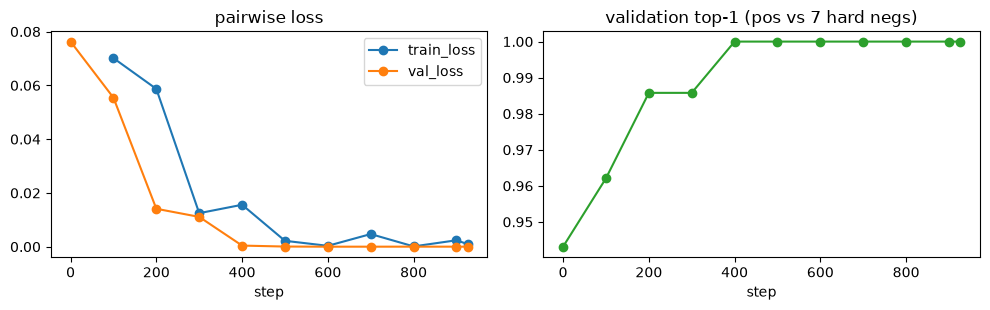

,step,train_loss,val_loss,val_acc
0,0,NaN,0.076289,0.943128
1,100,0.070135,0.055423,0.962085
2,200,0.058688,0.014114,0.985782
3,300,0.012483,0.011095,0.985782
4,400,0.015603,0.000423,1.000000
5,500,0.002198,0.000065,1.000000
6,600,0.000336,0.000013,1.000000
7,700,0.004707,0.000017,1.000000
8,800,0.000121,0.000026,1.000000
9,900,0.002401,0.000024,1.000000


In [3]:
h = pd.DataFrame({k: hist[k] for k in ("step", "train_loss", "val_loss", "val_acc")})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
h.plot(x="step", y=["train_loss", "val_loss"], ax=ax[0], marker="o"); ax[0].set_title("pairwise loss")
h.plot(x="step", y="val_acc", ax=ax[1], marker="o", color="C2", legend=False); ax[1].set_title("validation top-1 (pos vs 7 hard negs)")
plt.tight_layout(); plt.savefig(config.ARTIFACT_DIR / "reranker_training_curve.png", dpi=120); plt.show()
h

### Before vs after fine-tuning (200 held-out queries, top-5 after reranking)

In [4]:
cmp = pd.DataFrame({"hybrid RRF (no reranker)": comp["hybrid_rrf_no_rerank"],
                    "pre-trained bge-reranker-large": comp["pretrained_reranker"],
                    "fine-tuned bge-reranker-large": comp["finetuned_reranker"]}).T.round(4)
cmp["hit@1 errors"] = ((1 - cmp["hit@1"]) * 200).round().astype(int)
cmp

,context_precision,context_recall,mrr,hit@1,answer_chunk@1,hit@1 errors
hybrid RRF (no reranker),0.8584,0.995,0.8658,0.760,0.765,48
pre-trained bge-reranker-large,0.9744,1.000,0.9862,0.975,0.975,5
fine-tuned bge-reranker-large,0.9722,0.995,0.9950,0.995,0.995,1


### Which queries changed?

In [5]:
from rag.corpus import load_jsonl
from rag.retrieval import HybridRetriever
from rag.reranker import CrossEncoderReranker
from rag import metrics, store
store.ensure_qdrant()
r = HybridRetriever(); test = load_jsonl(config.EVAL_DIR / "test_qa.jsonl")
base = CrossEncoderReranker(config.RERANKER_MODEL); tuned = CrossEncoderReranker(config.FINETUNED_RERANKER_DIR)
diff, pos_scores, neg_scores = [], {"pre-trained": [], "fine-tuned": []}, {"pre-trained": [], "fine-tuned": []}
for row in test:
    c = r.retrieve(row["question"])
    out = {}
    for name, m in (("pre-trained", base), ("fine-tuned", tuned)):
        top = m.rerank(row["question"], c, 30, None)
        rel = metrics.relevance(top, row["doc"], row["page"])
        out[name] = (top[0]["doc"], top[0]["page"], rel[0])
        pos_scores[name] += [t["rerank_score"] for t, x in zip(top, rel) if x]
        neg_scores[name] += [t["rerank_score"] for t, x in zip(top, rel) if not x]
    if out["pre-trained"][2] != out["fine-tuned"][2]:
        diff.append({"question": row["question"], "gold": f'{row["doc"]} p{row["page"]}',
                     "pre-trained top-1": f'{out["pre-trained"][0]} p{out["pre-trained"][1]}',
                     "fine-tuned top-1": f'{out["fine-tuned"][0]} p{out["fine-tuned"][1]}'})
pd.DataFrame(diff)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

,question,gold,pre-trained top-1,fine-tuned top-1
0,What is the most liquid the HX-360 can move per minute?,HX_Pump_Series_Technical_Specification.docx p9,HX_Pump_Selection_Guide.md p8,HX_Pump_Series_Technical_Specification.docx p9
1,What is the most liquid the HX-600 can move per minute?,HX_Pump_Series_Technical_Specification.docx p13,HX_Pump_Selection_Guide.md p12,HX_Pump_Series_Technical_Specification.docx p13
2,How high can the HX-600 lift water?,HX_Pump_Series_Technical_Specification.docx p13,HX_Pump_Selection_Guide.md p12,HX_Pump_Series_Technical_Specification.docx p13
3,How many major nonconformities did the auditors find at Polaris Polymers?,Supplier_Audit_Report_2025.pdf p1,Supplier_Audit_Report_2025.pdf p2,Supplier_Audit_Report_2025.pdf p1
4,Which auditor was the lead auditor for Polaris Polymers?,Supplier_Audit_Report_2025.pdf p1,Supplier_Audit_Report_2025.pdf p2,Supplier_Audit_Report_2025.pdf p1
5,What kind of job was WO-26226?,maintenance_work_orders_2026.csv p18,maintenance_work_orders_2026.csv p20,maintenance_work_orders_2026.csv p18


### Score separation and the strict cutoff
Fine-tuning widens the margin between relevant and irrelevant passages, which is what lets a fixed cutoff drop clutter from the context window without losing evidence.

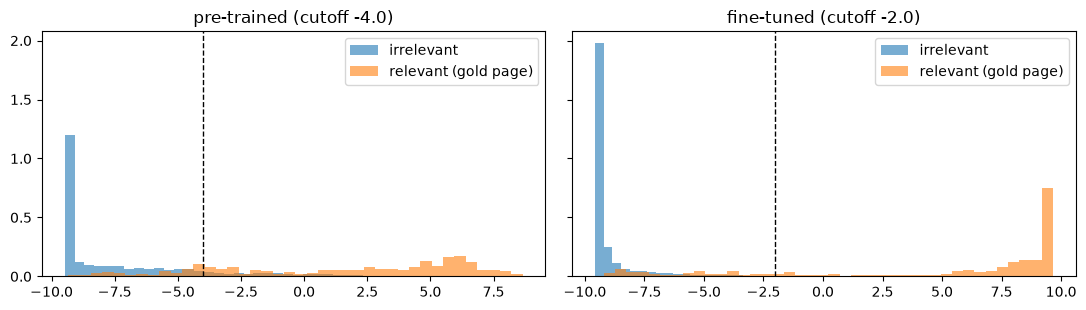

pre-trained  cutoff -4.0: relevant kept 0.835   irrelevant removed: 0.854   median margin: 11.71
fine-tuned   cutoff -2.0: relevant kept 0.775   irrelevant removed: 0.990   median margin: 17.57


In [6]:
import numpy as np
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, name in zip(ax, ("pre-trained", "fine-tuned")):
    a.hist(neg_scores[name], bins=40, alpha=.6, label="irrelevant", density=True)
    a.hist(pos_scores[name], bins=40, alpha=.6, label="relevant (gold page)", density=True)
    cut = config.RERANK_MIN_SCORE if name == "pre-trained" else config.RERANK_MIN_SCORE_FINETUNED
    a.axvline(cut, color="k", ls="--", lw=1); a.set_title(f"{name} (cutoff {cut})"); a.legend()
plt.tight_layout(); plt.savefig(config.ARTIFACT_DIR / "reranker_score_separation.png", dpi=120); plt.show()
for name in ("pre-trained", "fine-tuned"):
    p, n = np.array(pos_scores[name]), np.array(neg_scores[name])
    cut = config.RERANK_MIN_SCORE if name == "pre-trained" else config.RERANK_MIN_SCORE_FINETUNED
    print(f"{name:12s} cutoff {cut}: relevant kept {np.mean(p >= cut):.3f}   irrelevant removed: {np.mean(n < cut):.3f}"
          f"   median margin: {np.median(p) - np.median(n):.2f}")